Test pipeline.py:

In [16]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, '../src')

from lunarmag import analyse_pass
res = analyse_pass('2013-12-04/00:12', probe='b', monitor='c')
for k, v in res['summary'].items():
    print(f'{k:20s} {v}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


09-Nov-26 15:13:11: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
09-Nov-26 15:13:12: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
09-Nov-26 15:13:13: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
09-Nov-26 15:13:14: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
09-Nov-26 15:13:15: time_clip: thc_fgh_btotal has no data in requested range
09-Nov-26 15:13:15: time_clip: thc_fgh_gse has no data in requested range
09-Nov-26 15:13:15: time_clip: thc_fgh_gsm has no data in requested range
09-Nov-26 15:13:16: time_clip: thc_fgh_dsl has no data in requested range
09-Nov-26 15:13:16: time_clip: thc_fgh_ssl has no data in requested range
09-Nov-26 15:13:16: Eclipse correction status for probe ['b', 'c']:
09-Nov-26 15:13:16: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and

t_peri               1386115920.0
min_alt_km           14.786443151060894
lon_peri             85.34572612186673
lat_peri             -0.2604329868989033
sza_peri             79.63348192587993
shadow_s             780.0
monitor_upstream     True
monitor_in_shadow    False
bg_window            (np.float64(1386115440.0), np.float64(1386115620.0))
bg_shift             12.0
bg_r                 0.9402930783192042
bg_sigma             0.3999260037789166
bg_ok                True
post_shift           15.0
post_sigma           2.1400452114208863
n_used               262
shadow_pad           120.0
peak_svm             4.683686683803501
peak_dB              6.515041633302202
peak_dBi             5.717913417051809
snr                  16.29061769362661
frac_above_3sigma    0.5114503816793893
compression_nT       -0.6883759259395111
shear_deg            84.98069901189739


Post-pass fit is poor: noise floor higher than before periapsis and well over sigma=0.5 threshold. 
 
peak_dB is higher than at periapsis-- why?

compression negative-- interaction field points against crustal field for strong crust?



Find out when each peak occurs:

In [19]:
import numpy as np
from pyspedas import time_double

T0 = time_double('2013-12-04/00:00')
ts = res['t'] - T0
use = (~res['shadow']) & (res['alt'] < 300) & np.all(np.isfinite(res['dB_enr']), axis=1)

for name, arr in [('SVM', res['svm_enr']), ('dB', res['dB_enr']), ('dBi', res['dBi_enr'])]:
    mag = np.linalg.norm(arr, axis=1)
    mag[~use] = np.nan
    k = np.nanargmax(mag)
    print(f'{name:4s} peak {mag[k]:5.2f} nT at {ts[k]:6.0f} s, altitude {res["alt"][k]:6.1f} km')

SVM  peak  4.68 nT at    674 s, altitude   16.0 km
dB   peak  8.88 nT at   1191 s, altitude  154.9 km
dBi  peak  9.02 nT at   1191 s, altitude  154.9 km


Peak dB does not come from crust-- probably instrument effect at shadow edge.

Plot components from res to look at rotated data:

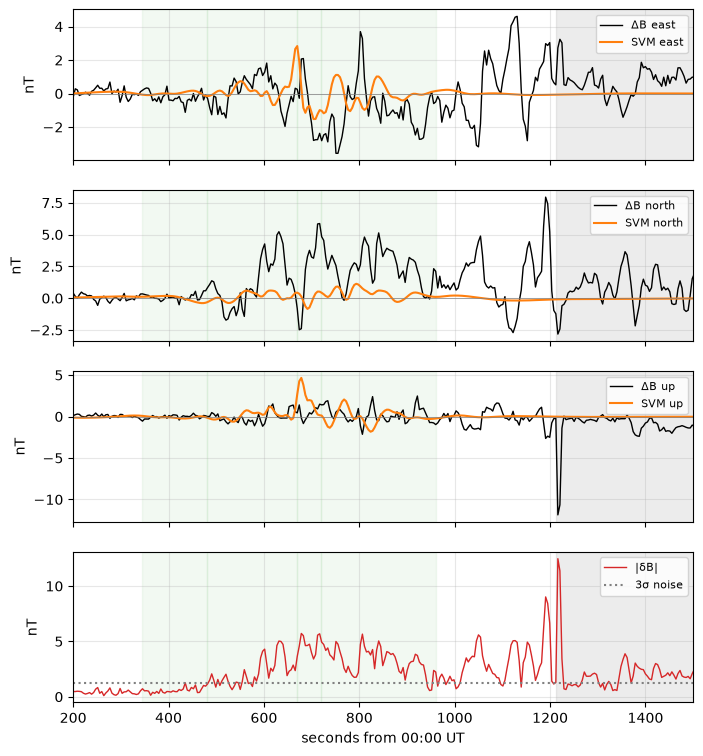

In [20]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(4, 1, sharex=True, figsize=(8, 9))
names = ['east', 'north', 'up']
for i, ax in enumerate(axs[:3]):
    ax.plot(ts, res['dB_enr'][:, i], color='k', lw=1, label=f'ΔB {names[i]}')
    ax.plot(ts, res['svm_enr'][:, i], color='C1', lw=1.5, label=f'SVM {names[i]}')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_ylabel('nT'); ax.legend(loc='upper right', fontsize=8)

axs[3].plot(ts, np.linalg.norm(res['dBi_enr'], axis=1), color='C3', lw=1, label='|δB|')
axs[3].axhline(3 * res['fit']['sigma_mag'], color='grey', ls=':', label='3σ noise')
axs[3].set_ylabel('nT'); axs[3].set_xlabel('seconds from 00:00 UT'); axs[3].legend(fontsize=8)

for ax in axs:
    ax.grid(True, alpha=0.3)
    for a, b in [(345, 480), (480, 670), (670, 720), (720, 960)]:
        ax.axvspan(a, b, color='C2', alpha=0.06) # Sawyer's intervals
    ax.axvspan(ts[res['shadow']].min(), ts.max(), color='grey', alpha=0.15) # shadow
axs[-1].set_xlim(200, 1500)
plt.show()

dB spike caused largely by spike in SVM up and occurs at edge of shadow region, consistent with instrument effect hypothesis. Measured lunar effect carried mainly in north component. Therefore need shadow edge buffer?

Check shadow buffer:

In [21]:
r = analyse_pass('2013-12-04/00:12', shadow_pad=120)
t0 = time_double('2013-12-04/00:00')
print('first shadow sample (FGM):', r['t'][r['shadow']][0] - t0)

09-Nov-26 15:19:00: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
09-Nov-26 15:19:01: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
09-Nov-26 15:19:01: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
09-Nov-26 15:19:01: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
09-Nov-26 15:19:03: time_clip: thc_fgh_btotal has no data in requested range
09-Nov-26 15:19:03: time_clip: thc_fgh_gse has no data in requested range
09-Nov-26 15:19:03: time_clip: thc_fgh_gsm has no data in requested range
09-Nov-26 15:19:03: time_clip: thc_fgh_dsl has no data in requested range
09-Nov-26 15:19:03: time_clip: thc_fgh_ssl has no data in requested range
09-Nov-26 15:19:03: Eclipse correction status for probe ['b', 'c']:
09-Nov-26 15:19:03: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and

first shadow sample (FGM): 1212.0360133647919


Problem: shadow falls between two samples, and buffer starts at first shadowed sample, which lies outside the actual shadow interval. 

Fix: set shadow buffer by starting the interval at the last lit sample inside the first shadowed sample. 

In [22]:
t0 = time_double('2013-12-04/00:00')
pads = [0, 60, 120, 180]
runs = {p: analyse_pass('2013-12-04/00:12', shadow_pad=p) for p in pads}

09-Nov-26 15:47:20: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
09-Nov-26 15:47:21: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
09-Nov-26 15:47:21: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
09-Nov-26 15:47:22: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
09-Nov-26 15:47:23: time_clip: thc_fgh_btotal has no data in requested range
09-Nov-26 15:47:23: time_clip: thc_fgh_gse has no data in requested range
09-Nov-26 15:47:23: time_clip: thc_fgh_gsm has no data in requested range
09-Nov-26 15:47:24: time_clip: thc_fgh_dsl has no data in requested range
09-Nov-26 15:47:24: time_clip: thc_fgh_ssl has no data in requested range
09-Nov-26 15:47:24: Eclipse correction status for probe ['b', 'c']:
09-Nov-26 15:47:24: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and

Summary table:

In [23]:
import pandas as pd

cols = ['n_used', 'peak_dB', 'peak_dBi', 'snr', 'frac_above_3sigma','compression_nT', 'post_shift', 'post_sigma']
table = pd.DataFrame({p: r['summary'] for p, r in runs.items()}).T[cols]
table['cut_at_s'] = [r['t'][r['use']].max() - t0 for r in runs.values()]
table

,n_used,peak_dB,peak_dBi,snr,frac_above_3sigma,compression_nT,post_shift,post_sigma,cut_at_s
0,276,8.882534,9.016497,22.210445,0.536232,-0.688376,45.0,2.472041,1199.227987
60,262,6.515042,5.717913,16.290618,0.51145,-0.688376,15.0,2.140045,1139.461399
120,248,6.515042,5.717913,16.290618,0.495968,-0.688376,16.0,2.050849,1079.694336
180,234,6.515042,5.717913,16.290618,0.465812,-0.688376,14.0,1.592984,1019.926753


Conclusion: outer fix successful, peaks settle at pad=60, frac_above_3sigma keeps falling with larger pad (wake contamination or interaction?), compression does not change so buffer does not touch strong crust samples, post-fit still poor (need to be less than 0.5 nT). Check where peaks occur:

In [24]:
def peak_where(r, key):
    """Size, time (s from 00:00) and altitude of the largest |vector| among used samples."""
    u = r['use']
    mag = np.linalg.norm(r[key][u], axis=1)
    k = np.argmax(mag)
    return mag[k], r['t'][u][k] - t0, r['alt'][u][k]

for p, r in runs.items():
    print(f'pad {p:>3} s')
    for key in ['svm_enr', 'dB_enr', 'dBi_enr']:
        v, ts, a = peak_where(r, key)
        print(f'  {key:8s} peak {v:5.2f} nT at {ts:6.0f} s, altitude {a:6.1f} km')

pad   0 s
  svm_enr  peak  4.68 nT at    674 s, altitude   16.0 km
  dB_enr   peak  8.88 nT at   1191 s, altitude  154.9 km
  dBi_enr  peak  9.02 nT at   1191 s, altitude  154.9 km
pad  60 s
  svm_enr  peak  4.68 nT at    674 s, altitude   16.0 km
  dB_enr   peak  6.52 nT at    713 s, altitude   14.8 km
  dBi_enr  peak  5.72 nT at    678 s, altitude   15.8 km
pad 120 s
  svm_enr  peak  4.68 nT at    674 s, altitude   16.0 km
  dB_enr   peak  6.52 nT at    713 s, altitude   14.8 km
  dBi_enr  peak  5.72 nT at    678 s, altitude   15.8 km
pad 180 s
  svm_enr  peak  4.68 nT at    674 s, altitude   16.0 km
  dB_enr   peak  6.52 nT at    713 s, altitude   14.8 km
  dBi_enr  peak  5.72 nT at    678 s, altitude   15.8 km


Both peaks move onto anomaly at pad=60. Why??

Checking post window:

In [27]:
r = analyse_pass('2013-12-04/00:12', shadow_pad=60)
s = r['summary']
print('post window (s from 00:00):', [w - t0 for w in s['post_window']])
print('post shift:', s['post_shift'], ' post sigma:', round(s['post_sigma'], 2))

09-Nov-26 17:40:12: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
09-Nov-26 17:40:13: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
09-Nov-26 17:40:13: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
09-Nov-26 17:40:13: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
09-Nov-26 17:40:15: time_clip: thc_fgh_btotal has no data in requested range
09-Nov-26 17:40:15: time_clip: thc_fgh_gse has no data in requested range
09-Nov-26 17:40:15: time_clip: thc_fgh_gsm has no data in requested range
09-Nov-26 17:40:15: time_clip: thc_fgh_dsl has no data in requested range
09-Nov-26 17:40:15: time_clip: thc_fgh_ssl has no data in requested range
09-Nov-26 17:40:15: Eclipse correction status for probe ['b', 'c']:
09-Nov-26 17:40:15: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and

post window (s from 00:00): [np.float64(930.0), np.float64(1110.0)]
post shift: 15.0  post sigma: 2.14


Obtain same resilts as before, so extending window did not help. Either:

(a) code wrong, or

(b) no clean SW data within reach.

Diagnose:

In [28]:
from pyspedas import get_data
from lunarmag import load_track, shadow_intervals

b, c = get_data('thb_fgs_gse'), get_data('thc_fgs_gse')
print('THB data ends at', b.times[-1] - t0, 's   THC data ends at', c.times[-1] - t0, 's')
print('shadow_s:', s['shadow_s'])

trk_long = load_track('b', ['2013-12-04/00:00', '2013-12-04/01:30'])
print('shadow intervals (s from 00:00):',
      [(a - t0, e - t0) for a, e in shadow_intervals(trk_long['t'], trk_long['shadow'])])

THB data ends at 4438.028198719025 s   THC data ends at 4438.270596504211 s
shadow_s: 3180.0


09-Nov-26 17:49:56: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf


shadow intervals (s from 00:00): [(np.float64(1260.0), np.float64(4860.0))]


Conclusion: THB in shadow for a full hour after periapsis, no sunlit post-pass data within extended search. Cannot accurately do post-pass check. 